# URN4-M SVM Experiment: Chicago vs Kano vs Shenyang vs Berlin

This notebook replicates the city-replication SVM pipeline using four city morphologies:
- Chicago (Gridiron)
- Kano (Chaotic)
- Shenyang (Linear)
- Berlin (Tributary)

Parameters:
- Subgraphs per city: 800
- Big-graph radius: 2000 m
- Local subgraph radius: 300 m


In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path().resolve().parent))

from src.graph_utils import compute_Q, kttw
from src.graph_dataset_preparation import ensure_unique_edge_weights


In [2]:
import osmnx as ox
import networkx as nx
import numpy as np
from tqdm import tqdm

SEED = 42
SUBGRAPHS_PER_CITY = 800
R_GLOBAL = 2000
R_LOCAL = 300
NETWORK_TYPE = "drive"
MAX_ATTEMPTS_FACTOR = 50

CITY_CONFIG = {
    "Chicago": (41.87, -87.63),
    "Kano": (12.01, 8.59),
    "Shenyang": (41.80, 123.43),
    "Berlin": (52.52, 13.40),
}

np.random.seed(SEED)
ox.settings.use_cache = True
ox.settings.log_console = False


In [3]:
def has_cycle(G):
    if G.number_of_nodes() < 3:
        return False
    if not nx.is_connected(G):
        return False
    return not nx.is_forest(G)


def extract_local_graph(G_large, center_node, radius):
    nodes_within_radius = nx.single_source_dijkstra_path_length(
        G_large,
        center_node,
        cutoff=radius,
        weight="length",
    ).keys()

    G_sub = G_large.subgraph(nodes_within_radius).copy()

    if G_sub.number_of_edges() == 0:
        return None

    G_sub = ox.convert.to_undirected(G_sub)
    G_sub.remove_nodes_from(list(nx.isolates(G_sub)))

    if G_sub.number_of_edges() == 0:
        return None

    if not nx.is_connected(G_sub):
        largest_cc = max(nx.connected_components(G_sub), key=len)
        G_sub = G_sub.subgraph(largest_cc).copy()

    if not has_cycle(G_sub):
        return None

    return G_sub


def generate_urn4_m_cycle_only():
    all_graphs = []
    graph_city_labels = []

    for city_name, (lat, lon) in CITY_CONFIG.items():
        print(f"\nDownloading large graph for {city_name}...")

        G_large = ox.graph_from_point(
            (lat, lon),
            dist=R_GLOBAL,
            network_type=NETWORK_TYPE,
            simplify=True,
        )
        G_large = ox.convert.to_undirected(G_large)
        nodes = list(G_large.nodes)

        print(
            f"Sampling {SUBGRAPHS_PER_CITY} cycle-containing graphs from {city_name}..."
        )

        accepted = 0
        attempts = 0
        max_attempts = SUBGRAPHS_PER_CITY * MAX_ATTEMPTS_FACTOR

        pbar = tqdm(total=SUBGRAPHS_PER_CITY, desc=f"{city_name}", leave=False)

        while accepted < SUBGRAPHS_PER_CITY:
            center_node = np.random.choice(nodes)
            G_local = extract_local_graph(G_large, center_node, R_LOCAL)

            attempts += 1

            if G_local is not None:
                all_graphs.append(G_local)
                graph_city_labels.append(city_name)
                accepted += 1
                pbar.update(1)

            if attempts >= max_attempts and accepted < SUBGRAPHS_PER_CITY:
                pbar.close()
                raise RuntimeError(
                    f"Failed to sample enough cycle-containing subgraphs for {city_name}. "
                    f"Accepted={accepted}, attempts={attempts}, max_attempts={max_attempts}."
                )

        pbar.close()
        print(f"Accepted {accepted} graphs after {attempts} attempts.")

    return all_graphs, graph_city_labels


In [4]:
graphs, labels = generate_urn4_m_cycle_only()

print("\nDataset generated.")
print(f"Total graphs: {len(graphs)}")

label_counts = {city: int(np.sum(np.array(labels) == city)) for city in CITY_CONFIG}
print("Graphs per city:", label_counts)



Sampling 800 cycle-containing graphs from Chicago...


Accepted 800 graphs after 935 attempts.

Sampling 800 cycle-containing graphs from Kano...


Accepted 800 graphs after 822 attempts.

Sampling 800 cycle-containing graphs from Shenyang...


Accepted 800 graphs after 945 attempts.

Sampling 800 cycle-containing graphs from Berlin...


Accepted 800 graphs after 943 attempts.

Dataset generated.
Total graphs: 3200
Graphs per city: {'Chicago': 800, 'Kano': 800, 'Shenyang': 800, 'Berlin': 800}


In [5]:
for i in range(len(graphs)):
    graphs[i] = graphs[i].to_undirected()

for G in graphs:
    if G.is_multigraph():
        for _, _, key, data in G.edges(keys=True, data=True):
            data["weight"] = float(data.get("length", 1.0))
    else:
        for _, _, data in G.edges(data=True):
            data["weight"] = float(data.get("length", 1.0))

graphs = ensure_unique_edge_weights(graphs)


In [6]:
no_hole_indices = [i for i, G in enumerate(graphs) if nx.is_forest(G)]
print("Graphs without holes (acyclic):", len(no_hole_indices))


Graphs without holes (acyclic): 0


In [7]:
len(graphs)

3200

(<Figure size 800x800 with 1 Axes>, <Axes: >)

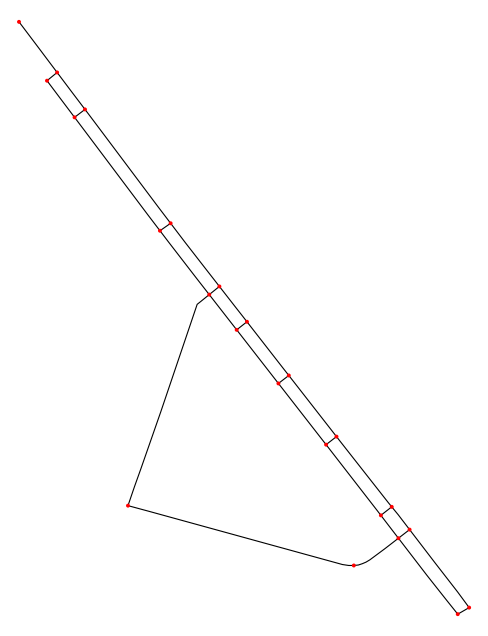

In [8]:
ox.plot_graph(
        graphs[2500],
        node_size=8,          # vertices visible
        node_color="red",
        edge_linewidth=0.8,   # edges visible
        edge_color="black",
        bgcolor="white",
        show=False,
        close=False,
    )

In [ ]:
Q_matrices = [compute_Q(G) for G in tqdm(graphs, desc="Computing Q")]

n_graphs = len(graphs)
gamma = 1.0
kts = np.zeros((n_graphs, n_graphs), dtype=float)

for i in tqdm(range(n_graphs), desc="Building kernel matrix"):
    kts[i, i] = 1.0
    for j in range(i + 1, n_graphs):
        kij = kttw(Q_matrices[i], Q_matrices[j], gamma=gamma)
        kts[i, j] = kij
        kts[j, i] = kij

print("Kernel matrix shape:", kts.shape)

Building kernel matrix: 100%|██████████| 3200/3200 [02:11<00:00, 24.41it/s] 

Kernel matrix shape: (3200, 3200)


In [10]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

labels = np.array(labels)
clf = SVC(kernel="precomputed")
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

scores = cross_val_score(clf, kts, labels, cv=cv, n_jobs=-1)

print("Fold accuracies:", np.round(scores, 4))
print("Mean accuracy:", scores.mean())
print("Std accuracy:", scores.std())


Fold accuracies: [0.7719 0.7656 0.7812 0.7812 0.8219 0.825  0.7875 0.775  0.7688 0.75  ]
Mean accuracy: 0.7828125
Std accuracy: 0.02254552685678469
